# RetinaXAI — Uçtan Uca Pipeline (Optimize Edilmiş Versiyon)

Bu notebook tek oturumda (single session) baştan sona çalışacak şekilde tasarlandı:
1. Kurulum
2. Data Augmentation ile Model Eğitimi (class-weighted loss, cosine LR schedule, AMP)
3. Grad-CAM / Grad-CAM++ / EigenCAM (ince çözünürlüklü katman seçimi ile)
4. IDRiD Quantitative Validation (adaptif Otsu threshold + Gaussian smoothing ile IoU/Dice)
5. Severity-Stratified Sonuç Tablosu ve Görselleştirme

Önceki denemede IoU/Dice ~0.3-0.4 civarındaydı ve heatmap'ler retinanın geniş orta
bölgesine odaklanıyordu. Bunun iki temel nedeni vardı: (a) Grad-CAM'in en son
konvolüsyon katmanından (7x7 çözünürlük) alınması — çok kaba bir mekansal çözünürlük,
(b) sabit 0.5 threshold'un heatmap'i binary'e çevirirken lezyon boyutuna duyarsız olması.
Bu notebook'ta ikisi de düzeltildi.

## 1. Kurulum

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install grad-cam -q

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 69.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, EigenCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Cihaz: {device}")
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Cihaz: cuda
Tesla T4


## 2. Konfigürasyon (Path'ler ve Hiperparametreler)

Burayı kendi klasör yapına göre kontrol et, gerekirse değiştir.

In [3]:
# --- Path'ler ---
BASE = '/content/drive/MyDrive/retinaxai'
APTOS_CSV = f'{BASE}/data/aptos2019/subset_large.csv'
APTOS_IMG_DIR = f'{BASE}/data/aptos2019/subset_images_large'
IDRID_BASE = f'{BASE}/data/idrid'
IDRID_IMG_DIR = f'{IDRID_BASE}/images'
OUTPUT_DIR = f'{BASE}/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Hiperparametreler ---
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 30
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 6
NUM_CLASSES = 5
LABEL_SMOOTHING = 0.1

# --- Grad-CAM için threshold stratejisi ---
# 'otsu'  -> her görsel için kendi kontrastına göre adaptif eşik (önerilen)
# 'fixed' -> sabit threshold (aşağıdaki FIXED_THRESHOLD kullanılır)
THRESHOLD_MODE = 'otsu'
FIXED_THRESHOLD = 0.4
GAUSSIAN_BLUR_SIGMA = 1.0  # heatmap'i pikselsel kırılmalardan arındırmak için

## 3. Dataset ve Data Augmentation

Train transform içinde flip/rotation/color-jitter var — model retinanın genel
şeklini ezberlemesin, lezyon detaylarına baksın diye.

In [4]:
class APTOSDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_id = self.data.iloc[idx]['id_code']
        label = int(self.data.iloc[idx]['diagnosis'])
        img_path = os.path.join(self.img_dir, f'{img_id}.png')
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

full_dataset = APTOSDataset(APTOS_CSV, APTOS_IMG_DIR, transform=train_transform)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Validation setine augmentation uygulanmaz, sade eval_transform kullanılır
val_dataset.dataset = APTOSDataset(APTOS_CSV, APTOS_IMG_DIR, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Train: 1230 | Val: 308


## 4. Class Weights (Sınıf Dengesizliğini Telafi Etmek İçin)

APTOS'ta class 0 (No DR) diğerlerinden fazla. Bu, loss fonksiyonuna sınıf
ağırlığı olarak yansıtılır — az örnekli sınıflar (Severe, Proliferative)
eğitimde daha fazla önem kazanır.

In [5]:
labels_all = pd.read_csv(APTOS_CSV)['diagnosis'].values
class_counts = np.bincount(labels_all, minlength=NUM_CLASSES)
class_weights = class_counts.sum() / (NUM_CLASSES * np.maximum(class_counts, 1))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Sınıf sayıları:", class_counts)
print("Sınıf ağırlıkları:", class_weights)

Sınıf sayıları: [350 350 350 193 295]
Sınıf ağırlıkları: [0.87885714 0.87885714 0.87885714 1.59378238 1.04271186]


## 5. Model, Loss, Optimizer, Scheduler

In [6]:
model = models.efficientnet_b0(weights='IMAGENET1K_V1')
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]
/tmp/ipykernel_672/1620571969.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


In [8]:
# DataLoader'ları yeniden oluştur — num_workers=0, prefetch_factor çıkar
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # Colab'da 0 daha hızlı
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoader'lar yeniden oluşturuldu (num_workers=0)")

DataLoader'lar yeniden oluşturuldu (num_workers=0)


## 6. Eğitim Döngüsü (Mixed Precision + Early Stopping)

In [9]:
best_val_acc = 0.0
patience_counter = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | "
          f"LR: {scheduler.get_last_lr()[0]:.2e}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), f'{OUTPUT_DIR}/best_model.pth')
        print(f"  -> En iyi model güncellendi (Val Acc: {best_val_acc:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping: {PATIENCE} epoch boyunca iyileşme yok.")
            break

print(f"\nEğitim tamamlandı. En iyi Val Acc: {best_val_acc:.4f}")

/tmp/ipykernel_672/1181241790.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_672/1181241790.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_672/1181241790.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_672/1181241790.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Epoch [1/30] Train Loss: 1.3619 Acc: 0.5057 | Val Loss: 1.2607 Acc: 0.5779 | LR: 4.99e-05
  -> En iyi model güncellendi (Val Acc: 0.5779)
Epoch [2/30] Train Loss: 1.2643 Acc: 0.5715 | Val Loss: 1.1649 Acc: 0.6234 | LR: 4.95e-05
  -> En iyi model güncellendi (Val Acc: 0.6234)
Epoch [3/30] Train Loss: 1.1895 Acc: 0.5919 | Val Loss: 1.1054 Acc: 0.6266 | LR: 4.88e-05
  -> En iyi model güncellendi (Val Acc: 0.6266)
Epoch [4/30] Train Loss: 1.1172 Acc: 0.6317 | Val Loss: 1.0521 Acc: 0.6688 | LR: 4.78e-05
  -> En iyi model güncellendi (Val Acc: 0.6688)
Epoch [5/30] Train Loss: 1.0788 Acc: 0.6382 | Val Loss: 1.0134 Acc: 0.6818 | LR: 4.67e-05
  -> En iyi model güncellendi (Val Acc: 0.6818)
Epoch [6/30] Train Loss: 1.0299 Acc: 0.6780 | Val Loss: 1.0083 Acc: 0.6786 | LR: 4.52e-05
Epoch [7/30] Train Loss: 1.0161 Acc: 0.6837 | Val Loss: 0.9923 Acc: 0.6818 | LR: 4.36e-05
Epoch [8/30] Train Loss: 0.9722 Acc: 0.7024 | Val Loss: 0.9932 Acc: 0.6786 | LR: 4.17e-05
Epoch [9/30] Train Loss: 0.9522 Acc: 0.7

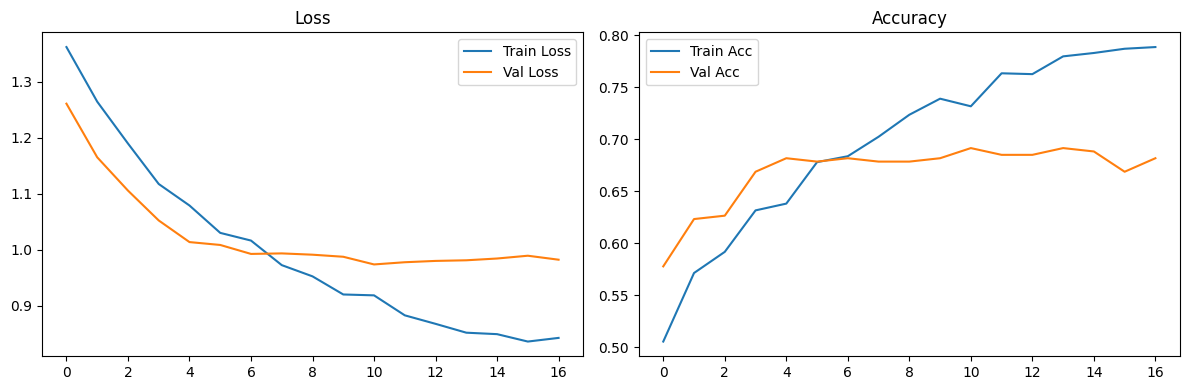

In [11]:
# Eğitim eğrilerini çiz
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title('Loss')
axes[0].legend()

axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_title('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_curves.png')
plt.show()

## 7. En İyi Modeli Geri Yükle

In [12]:
model.load_state_dict(torch.load(f'{OUTPUT_DIR}/best_model.pth'))
model.eval()
print("En iyi model yüklendi.")

En iyi model yüklendi.


## 8. Grad-CAM İçin Doğru Katmanı Seçme (Kritik Adım)

`model.features[-1]`, EfficientNet-B0'da 224x224 girdi için ~7x7'lik çok kaba
bir mekansal harita üretir — bu, heatmap'in neden geniş/orta bir bölgeye
yayıldığını açıklıyor. Aşağıdaki hücre, her bloğun ürettiği mekansal
çözünürlüğü (feature map boyutunu) yazdırır. Daha ince lezyon localizasyonu
için 14x14 civarı çözünürlük veren bir orta katman seçeceğiz.

In [13]:
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
hook_outputs = {}

def make_hook(name):
    def hook(module, inp, out):
        hook_outputs[name] = tuple(out.shape)
    return hook

handles = []
for idx, block in enumerate(model.features):
    handles.append(block.register_forward_hook(make_hook(f'features[{idx}]')))

with torch.no_grad():
    _ = model(dummy_input)

for h in handles:
    h.remove()

for name, shape in hook_outputs.items():
    print(f"{name}: {shape}")

features[0]: (1, 32, 112, 112)
features[1]: (1, 16, 112, 112)
features[2]: (1, 24, 56, 56)
features[3]: (1, 40, 28, 28)
features[4]: (1, 80, 14, 14)
features[5]: (1, 112, 14, 14)
features[6]: (1, 192, 7, 7)
features[7]: (1, 320, 7, 7)
features[8]: (1, 1280, 7, 7)


In [14]:
# Yukarıdaki çıktıya bakarak ~14x14 çözünürlük veren katmanı seç.
# EfficientNet-B0 için bu genellikle features[6] civarıdır; çıktıyı kontrol edip gerekirse değiştir.
FINE_LAYER_INDEX = 5
target_layer_fine = [model.features[FINE_LAYER_INDEX]]

print(f"Grad-CAM için kullanılacak katman: features[{FINE_LAYER_INDEX}] -> "
      f"{hook_outputs.get(f'features[{FINE_LAYER_INDEX}]')}")

Grad-CAM için kullanılacak katman: features[5] -> (1, 112, 14, 14)


In [15]:
cam_methods = {
    'GradCAM': GradCAM(model=model, target_layers=target_layer_fine),
    'GradCAM++': GradCAMPlusPlus(model=model, target_layers=target_layer_fine),
    'EigenCAM': EigenCAM(model=model, target_layers=target_layer_fine)
}
print("cam_methods tanımlandı:", list(cam_methods.keys()))

cam_methods tanımlandı: ['GradCAM', 'GradCAM++', 'EigenCAM']


## 9. Örnek Görsel Üzerinde Hızlı Görsel Kontrol

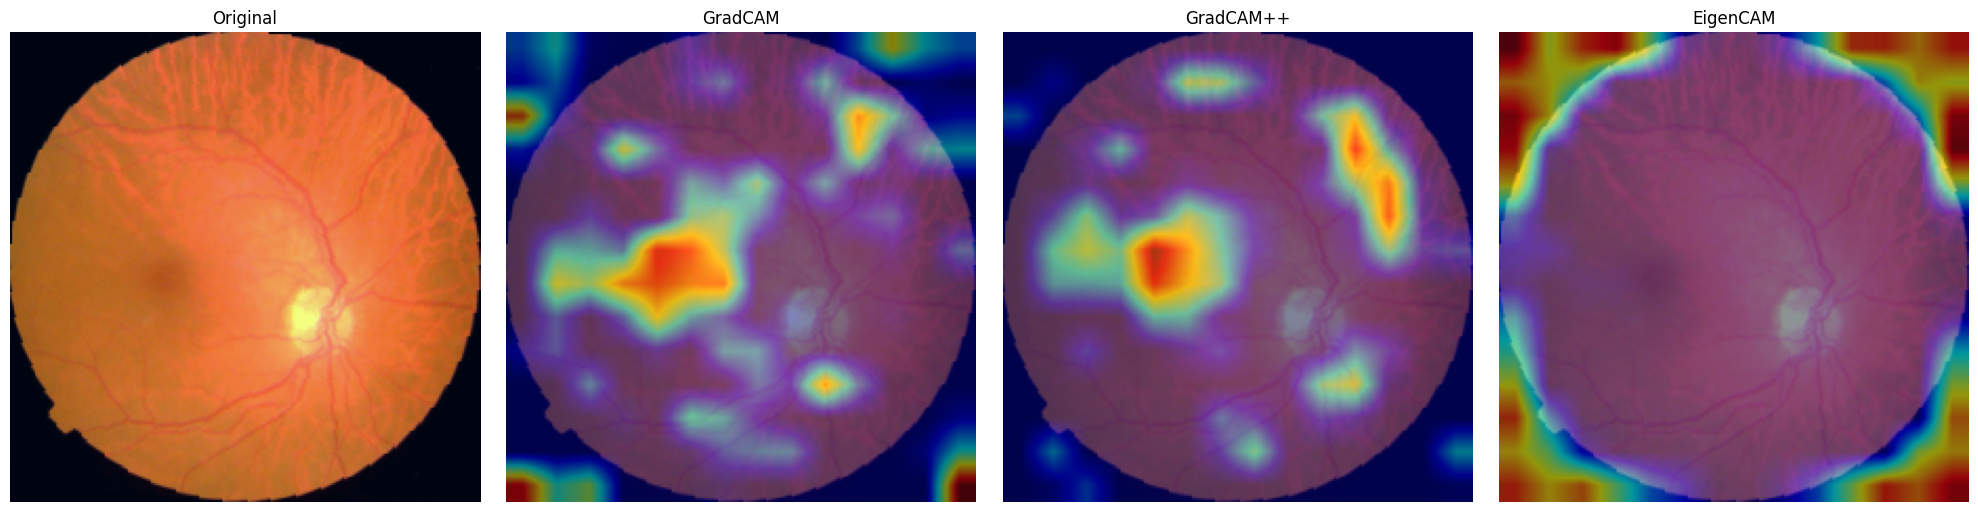

In [16]:
from pytorch_grad_cam.utils.image import show_cam_on_image

sample_image, sample_label = full_dataset[0]
input_tensor = sample_image.unsqueeze(0).to(device)
targets = [ClassifierOutputTarget(sample_label)]

img_np = sample_image.permute(1, 2, 0).cpu().numpy()
img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img_np)
axes[0].set_title('Original')
axes[0].axis('off')

for i, (name, cam) in enumerate(cam_methods.items()):
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)
    axes[i+1].imshow(visualization)
    axes[i+1].set_title(name)
    axes[i+1].axis('off')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/sample_gradcam_finelayer.png')
plt.show()

## 10. IDRiD — Lezyon Maskeleri ve Adaptif Threshold Fonksiyonları

`THRESHOLD_MODE = 'otsu'` ile her görsel kendi heatmap dağılımına göre
optimal bir eşik değeri bulur (sabit 0.5'in aksine). Ayrıca Gaussian blur ile
heatmap'teki pikselsel gürültü/kırılmalar yumuşatılır.

In [17]:
from skimage.filters import threshold_otsu
from scipy.ndimage import gaussian_filter

lesion_suffixes = {
    'Microaneurysms': 'MA',
    'Haemorrhages': 'HE',
    'HardExudates': 'EX',
    'SoftExudates': 'SE'
}

def get_combined_mask(image_id, target_size=(IMG_SIZE, IMG_SIZE)):
    combined = None
    for lesion_name, suffix in lesion_suffixes.items():
        mask_path = f'{IDRID_BASE}/masks/{lesion_name}/{image_id}_{suffix}.tif'
        if os.path.exists(mask_path):
            mask = Image.open(mask_path).convert('L')
            mask = mask.resize(target_size, Image.NEAREST)
            mask_np = np.array(mask) > 0
            combined = mask_np if combined is None else (combined | mask_np)
    if combined is None:
        combined = np.zeros(target_size, dtype=bool)
    return combined.astype(np.uint8)


def binarize_heatmap(heatmap, mode=THRESHOLD_MODE, fixed_threshold=FIXED_THRESHOLD,
                      blur_sigma=GAUSSIAN_BLUR_SIGMA):
    smoothed = gaussian_filter(heatmap, sigma=blur_sigma) if blur_sigma > 0 else heatmap

    if mode == 'otsu':
        # Otsu, tamamen düz (varyanssız) bir haritada patlayabilir; güvenli fallback ekliyoruz.
        try:
            thresh = threshold_otsu(smoothed)
        except ValueError:
            thresh = fixed_threshold
    else:
        thresh = fixed_threshold

    return (smoothed >= thresh).astype(np.uint8)


def compute_iou(binary_heatmap, mask):
    intersection = np.logical_and(binary_heatmap, mask).sum()
    union = np.logical_or(binary_heatmap, mask).sum()
    return intersection / union if union > 0 else 0.0


def compute_dice(binary_heatmap, mask):
    intersection = np.logical_and(binary_heatmap, mask).sum()
    total = binary_heatmap.sum() + mask.sum()
    return (2 * intersection) / total if total > 0 else 0.0

## 11. IDRiD Görselleri Üzerinde Toplu Değerlendirme

In [18]:
idrid_ids = sorted([f.replace('.jpg', '') for f in os.listdir(IDRID_IMG_DIR) if f.endswith('.jpg')])
print(f"Toplam IDRiD görseli: {len(idrid_ids)}")

def evaluate_image(image_id):
    img_path = f'{IDRID_IMG_DIR}/{image_id}.jpg'
    image = Image.open(img_path).convert('RGB')
    image_tensor = eval_transform(image)
    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        pred_class = torch.argmax(output, dim=1).item()

    targets = [ClassifierOutputTarget(pred_class)]
    mask = get_combined_mask(image_id)

    results = {}
    for name, cam in cam_methods.items():
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
        binary_cam = binarize_heatmap(grayscale_cam)
        iou = compute_iou(binary_cam, mask)
        dice = compute_dice(binary_cam, mask)
        results[name] = {'iou': iou, 'dice': dice}

    return pred_class, results, mask.sum()


all_results = []
for image_id in idrid_ids:
    try:
        pred_class, results, lesion_pixels = evaluate_image(image_id)
        row = {'image_id': image_id, 'predicted_class': pred_class, 'lesion_pixels': lesion_pixels}
        for method_name, scores in results.items():
            row[f'{method_name}_IoU'] = scores['iou']
            row[f'{method_name}_Dice'] = scores['dice']
        all_results.append(row)
    except Exception as e:
        print(f"Hata ({image_id}): {e}")

results_df = pd.DataFrame(all_results)
results_df.to_csv(f'{OUTPUT_DIR}/idrid_validation_results.csv', index=False)
print(f"Toplam işlenen görsel: {len(results_df)}")
results_df.head()

Toplam IDRiD görseli: 54
Toplam işlenen görsel: 54


,image_id,predicted_class,lesion_pixels,GradCAM_IoU,GradCAM_Dice,GradCAM++_IoU,GradCAM++_Dice,EigenCAM_IoU,EigenCAM_Dice
0,IDRiD_01,2,647,0.042714,0.081929,0.003073,0.006128,0.021516,0.042126
1,IDRiD_02,3,642,0.044989,0.086104,0.035721,0.068978,0.000064,0.000128
2,IDRiD_03,3,1958,0.097527,0.177722,0.077889,0.144521,0.000000,0.000000
3,IDRiD_04,1,275,0.000482,0.000963,0.004277,0.008518,0.000079,0.000158
4,IDRiD_05,1,87,0.000797,0.001592,0.005293,0.010531,0.001641,0.003277


## 12. Genel ve Severity-Stratified Sonuç Tabloları

In [19]:
score_cols = [c for c in results_df.columns if 'IoU' in c or 'Dice' in c]

print("Ortalama IoU/Dice Skorları (Tüm Görseller):")
print(results_df[score_cols].mean())

severity_summary = results_df.groupby('predicted_class')[score_cols].mean()
print("\nSeverity Bazlı Ortalama Skorlar:")
print(severity_summary)

severity_summary.to_csv(f'{OUTPUT_DIR}/severity_stratified_results.csv')

Ortalama IoU/Dice Skorları (Tüm Görseller):
GradCAM_IoU       0.039340
GradCAM_Dice      0.072419
GradCAM++_IoU     0.044142
GradCAM++_Dice    0.081780
EigenCAM_IoU      0.018052
EigenCAM_Dice     0.033310
dtype: float64

Severity Bazlı Ortalama Skorlar:
                 GradCAM_IoU  GradCAM_Dice  GradCAM++_IoU  GradCAM++_Dice  \
predicted_class                                                             
0                   0.005252      0.010383       0.009058        0.017865   
1                   0.000875      0.001747       0.005969        0.011832   
2                   0.030663      0.058577       0.044112        0.082934   
3                   0.094758      0.171286       0.084189        0.153309   
4                   0.100830      0.180140       0.091883        0.166501   

                 EigenCAM_IoU  EigenCAM_Dice  
predicted_class                               
0                    0.000321       0.000641  
1                    0.001636       0.003245  
2                

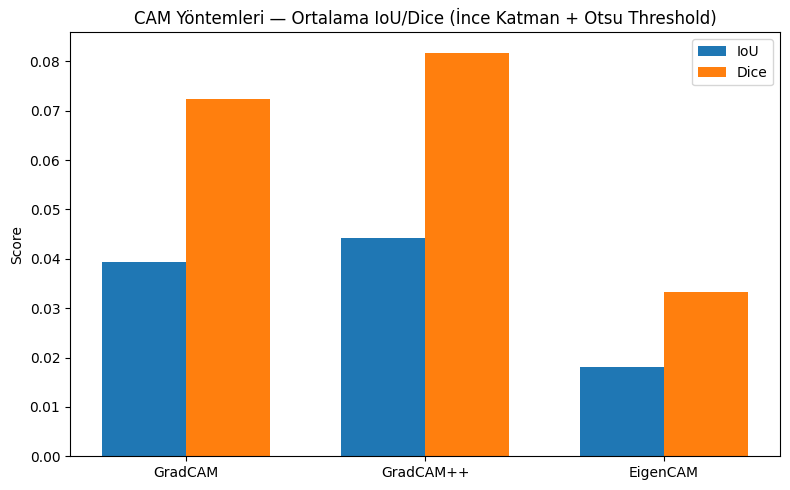

In [20]:
methods = list(cam_methods.keys())
iou_means = [results_df[f'{m}_IoU'].mean() for m in methods]
dice_means = [results_df[f'{m}_Dice'].mean() for m in methods]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, iou_means, width, label='IoU')
ax.bar(x + width/2, dice_means, width, label='Dice')
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel('Score')
ax.set_title('CAM Yöntemleri — Ortalama IoU/Dice (İnce Katman + Otsu Threshold)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/cam_comparison_chart.png')
plt.show()

## 13. Kalitatif Kontrol — Orijinal | Gerçek Maske | Heatmap

Sayısal skor düşük çıksa bile, görsel karşılaştırma bazen modelin lezyona
gerçekten yakın odaklandığını gösterebilir (raporda kanıt olarak değerlidir).

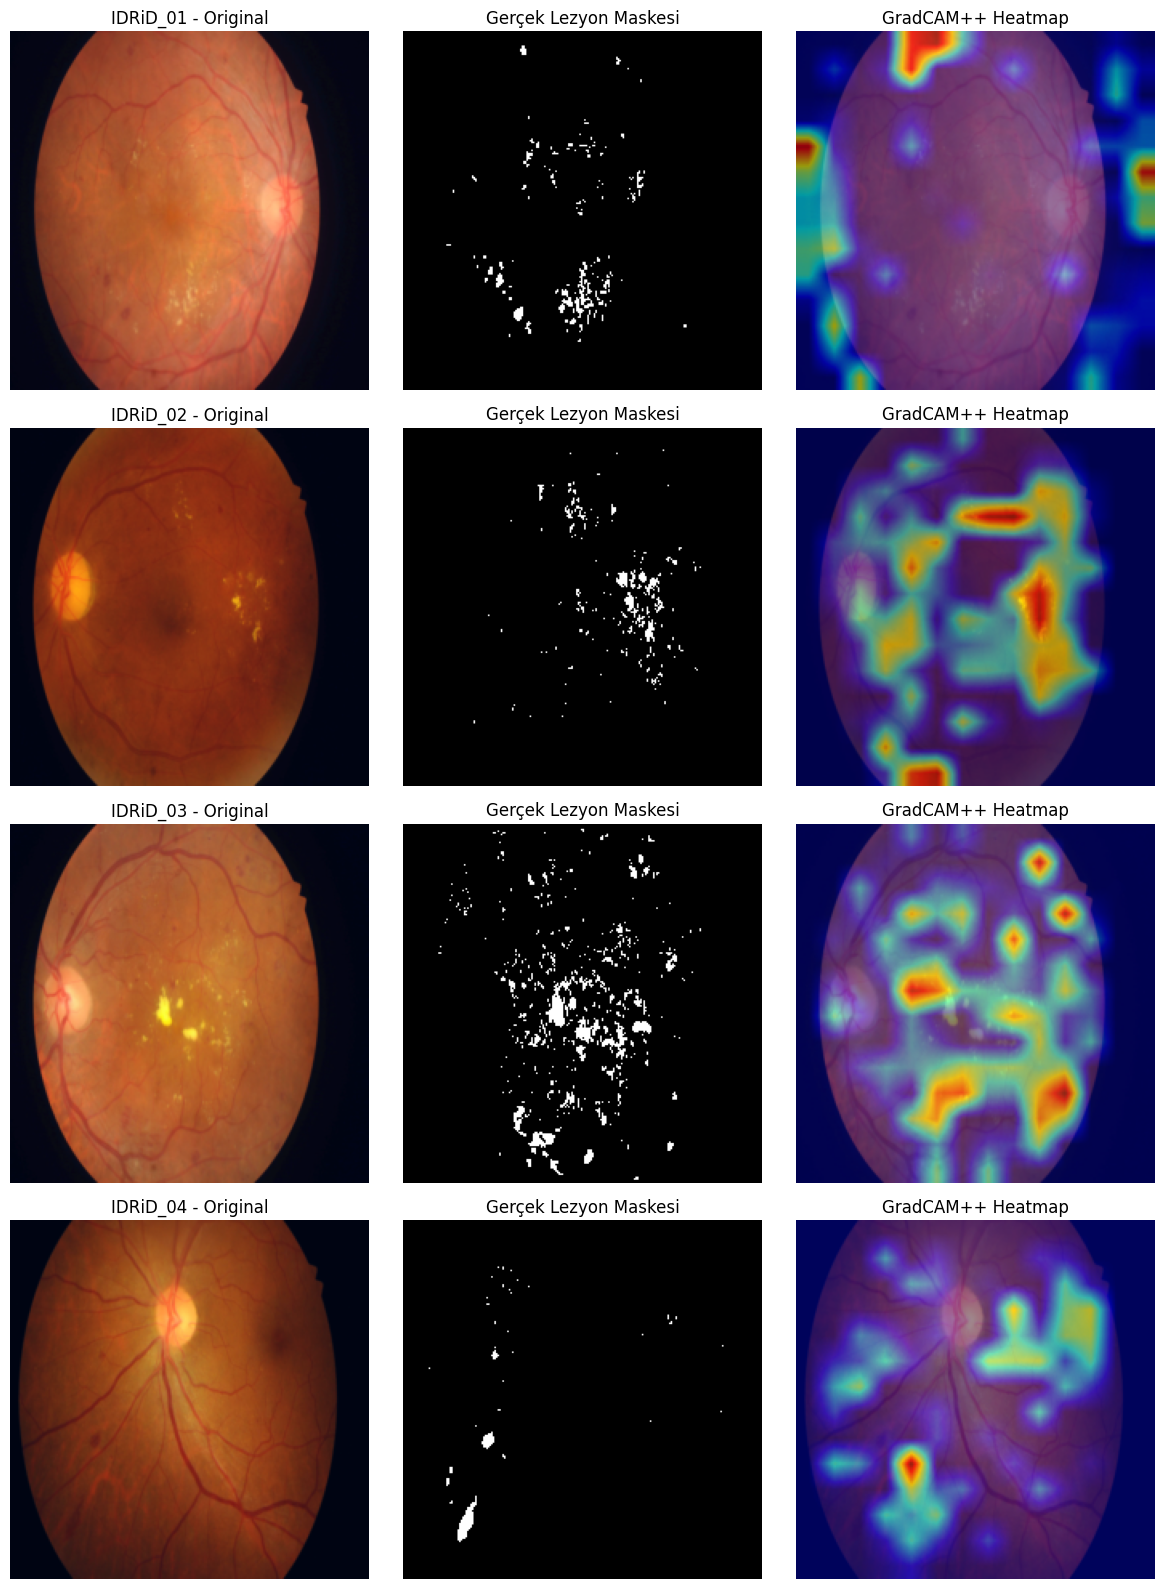

In [21]:
num_samples = 4
sample_ids = idrid_ids[:num_samples]

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))

for row, image_id in enumerate(sample_ids):
    img_path = f'{IDRID_IMG_DIR}/{image_id}.jpg'
    image = Image.open(img_path).convert('RGB')
    image_tensor = eval_transform(image)
    input_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        pred_class = torch.argmax(output, dim=1).item()

    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam_methods['GradCAM++'](input_tensor=input_tensor, targets=targets)[0]

    img_np = image_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())
    mask = get_combined_mask(image_id)
    visualization = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f'{image_id} - Original'); axes[row, 0].axis('off')
    axes[row, 1].imshow(mask, cmap='gray'); axes[row, 1].set_title('Gerçek Lezyon Maskesi'); axes[row, 1].axis('off')
    axes[row, 2].imshow(visualization); axes[row, 2].set_title('GradCAM++ Heatmap'); axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/qualitative_comparison.png')
plt.show()